# 00 · Exploratory data analysis of the source datasets

SokoRadar capstone · data understanding. This notebook looks at each raw dataset before any modelling: what it
contains, how complete it is, how it behaves over time, and what that means for the model. The cleaned and joined
data are explored further in `01_eda_and_data_quality.ipynb`.

| # | Dataset | Provider | File in `data/raw/` | Role in SokoRadar |
|---|---|---|---|---|
| 1 | [Kenya – Food Prices](https://data.humdata.org/dataset/wfp-food-prices-for-kenya) | WFP via HDX | `wfp_food_prices_ken.csv`, `wfp_markets_ken.csv` | Target: monthly market prices |
| 2 | [Rainfall indicators (CHIRPS)](https://data.humdata.org/dataset/ken-rainfall-subnational) | WFP and Climate Hazards Center via HDX | `ken-rainfall-subnat-full.csv` | Climate driver |
| 3 | [Vegetation index (MODIS NDVI)](https://data.humdata.org/dataset/ken-ndvi-subnational) | WFP and NASA via HDX | `ken-ndvi-subnat-full.csv` | Crop and pasture condition |
| 4 | [Exchange rates](https://www.centralbank.go.ke/rates/forex-exchange-rates/) | Central Bank of Kenya | `cbk_fx_historical.csv` | Exchange-rate driver |
| 5 | [Commodity prices (Pink Sheet)](https://www.worldbank.org/en/research/commodity-markets) | World Bank | `CMO-Historical-Data-Monthly.xlsx` | Global prices (tested) |
| 6 | [Real-Time Food Prices](https://data.humdata.org/dataset/kenya-real-time-prices) | World Bank via HDX | `real-time-food-prices-for-kenya.csv` | Goat prices for terms of trade |
| 7 | [Administrative boundaries](https://data.humdata.org/dataset/cod-ab-ken) | OCHA via HDX | `ken_admin1.geojson` (simplified copy in `config/`) | County shapes, market-to-county links |

The raw files are downloaded by `python -m sokoradar.pipeline run --stages ingest`. Shaded bands in the time plots
mark the 2010–11, 2016–17 and 2021–23 droughts.

In [1]:
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Polygon
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
from sokoradar.config import settings

RAW = ROOT / "data/raw"
FILES = {"wfp": "wfp_food_prices_ken.csv", "markets": "wfp_markets_ken.csv", "rain": "ken-rainfall-subnat-full.csv",
         "ndvi": "ken-ndvi-subnat-full.csv", "cbk": "cbk_fx_historical.csv", "pink": "CMO-Historical-Data-Monthly.xlsx",
         "rtfp": "real-time-food-prices-for-kenya.csv"}
missing = [f for f in FILES.values() if not (RAW / f).exists()]
assert not missing, f"Missing raw files {missing}: run `python -m sokoradar.pipeline run --stages ingest` first"

DROUGHTS = [("2010-10-01", "2011-09-01"), ("2016-10-01", "2017-08-01"), ("2021-10-01", "2023-03-01")]
def shade(ax):
    for a, b in DROUGHTS:
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color="#c92a2a", alpha=0.07, lw=0)
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
counties = pd.read_csv(ROOT / "config/counties.csv")
PCODE = counties.set_index("county").pcode

## 1. WFP food prices: the target

### 1.1 First look

In [2]:
wfp = pd.read_csv(RAW / FILES["wfp"], parse_dates=["date"])
print(f"{len(wfp):,} rows x {wfp.shape[1]} columns, {wfp.date.min():%b %Y} to {wfp.date.max():%b %Y}")
print(f"{wfp.market.nunique()} markets in {wfp.admin2.nunique()} admin areas, {wfp.commodity.nunique()} commodities")
wfp.head()

28,463 rows x 16 columns, Jan 2006 to Sep 2026
226 markets in 27 admin areas, 51 commodities


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2006-01-15,Coast,Mombasa,Mombasa,191,-4.05,39.67,cereals and tubers,Maize,51,KG,actual,Wholesale,KES,16.13,0.22
1,2006-01-15,Coast,Mombasa,Mombasa,191,-4.05,39.67,cereals and tubers,Maize (white),67,90 KG,actual,Wholesale,KES,1480.00,20.58
2,2006-01-15,Coast,Mombasa,Mombasa,191,-4.05,39.67,pulses and nuts,Beans,50,KG,actual,Wholesale,KES,33.63,0.47
3,2006-01-15,Coast,Mombasa,Mombasa,191,-4.05,39.67,pulses and nuts,Beans (dry),262,90 KG,actual,Wholesale,KES,3246.00,45.15
4,2006-01-15,Eastern,Kitui,Kitui,187,-1.37,38.02,cereals and tubers,Maize (white),67,KG,actual,Retail,KES,17.00,0.24


In [3]:
pd.DataFrame({"dtype": wfp.dtypes.astype(str), "missing": wfp.isna().sum(), "unique values": wfp.nunique()})

,dtype,missing,unique values
date,datetime64[us],0,249
admin1,str,68,7
admin2,str,68,27
market,str,0,226
market_id,int64,0,226
latitude,float64,68,182
longitude,float64,68,184
category,str,0,8
commodity,str,0,51
commodity_id,int64,0,51


In [4]:
print("Markets with a missing location:", wfp.loc[wfp.latitude.isna(), "market"].value_counts().to_dict())
print("Day of the month:", wfp.date.dt.day.value_counts().to_dict())
for col in ["currency", "pricetype", "priceflag"]:
    print(f"{col}:", wfp[col].value_counts().to_dict())

Markets with a missing location: {'Hola (Tana River)': 68}
Day of the month: {15: 28463}
currency: {'KES': 28463}
pricetype: {'Retail': 19081, 'Wholesale': 9382}
priceflag: {'actual': 18737, 'aggregate': 9468, 'actual,aggregate': 258}


- One row is one price: a market, a commodity, a unit, a price type and a month. Every date is the 15th, so the
  data is **monthly**.
- Only location fields have gaps, and all 68 belong to one market, *Hola (Tana River)*. The cleaning step places it
  using WFP's market list and its county.
- Every price is in Kenyan shillings. `usdprice` is WFP's own conversion to dollars, which section 5 uses to
  recover the exchange rate.
- `priceflag` marks prices collected in that month (`actual`) or averaged from more frequent collection
  (`aggregate`). Both are kept.

### 1.2 What is recorded

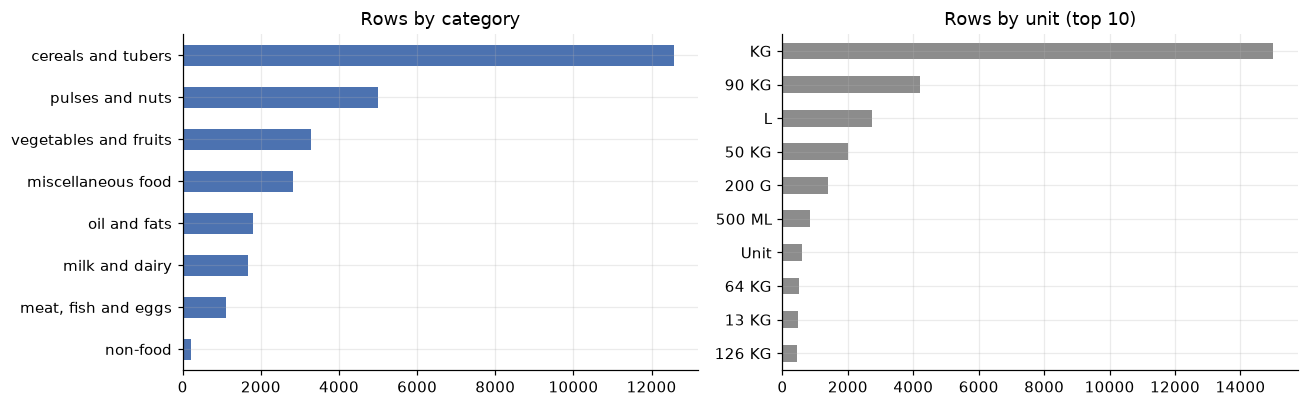

,rows
commodity,
Beans (dry),1878
Maize (white),1785
Maize,1548
Sugar,1436
Wheat flour,1420
Salt,1399
Beans,1391
Potatoes (Irish),1363
Sorghum,1103


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
wfp.category.value_counts().sort_values().plot.barh(ax=axes[0], color="#4c72b0", title="Rows by category")
wfp.unit.value_counts().head(10).sort_values().plot.barh(ax=axes[1], color="#8c8c8c", title="Rows by unit (top 10)")
for ax in axes:
    ax.set_ylabel("")
plt.tight_layout(); plt.show()
wfp.commodity.value_counts().head(12).rename("rows").to_frame()

Cereals and pulses make up most of the file. Units are mixed: the same maize is reported per kg and per 90 kg bag,
so prices must be converted to shillings per kg before they can be compared.

### 1.3 Coverage over time and across markets

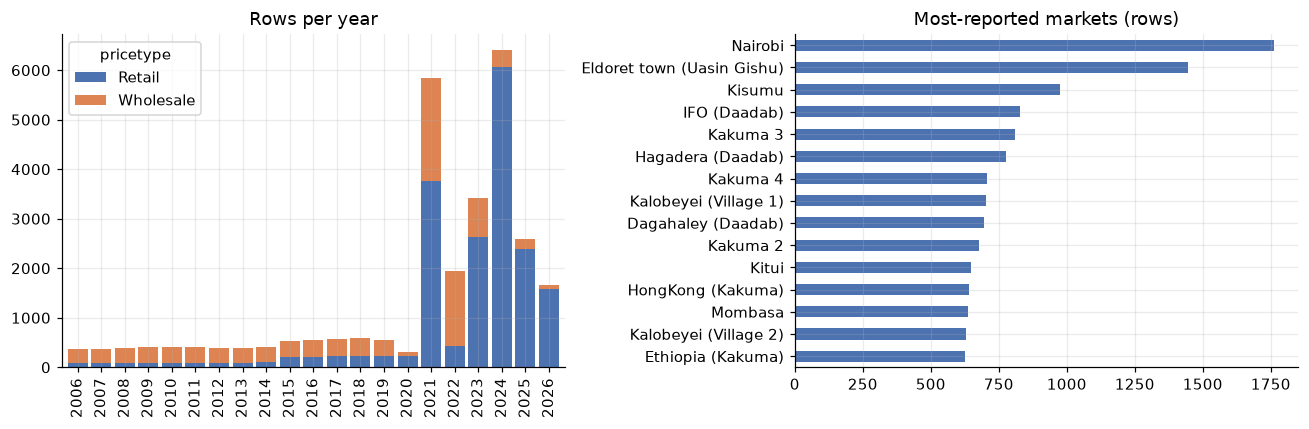

Markets with fewer than 12 rows in total: 25 of 226


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
(wfp.groupby([wfp.date.dt.year, "pricetype"]).size().unstack()
    .plot.bar(stacked=True, ax=axes[0], color=["#4c72b0", "#dd8452"], width=0.85, title="Rows per year"))
axes[0].set_xlabel("")
rows = wfp.market.value_counts()
rows.head(15).sort_values().plot.barh(ax=axes[1], color="#4c72b0", title="Most-reported markets (rows)")
axes[1].set_ylabel("")
plt.tight_layout(); plt.show()
print(f"Markets with fewer than 12 rows in total: {(rows < 12).sum()} of {len(rows)}")

Until 2020, WFP reported 300 to 600 prices a year, mostly from the big wholesale markets. From 2021, the
refugee-camp markets of Kakuma, Kalobeyei and Dadaab add thousands of retail prices a year. Coverage is uneven:
25 of the 226 markets have fewer than 12 prices in total.

### 1.4 The four staples and their units

In [7]:
from sokoradar.clean import commodity_map, unit_to_kg
cmap = commodity_map()
st = wfp[wfp.commodity.isin(cmap)].copy()
st["staple"] = st.commodity.map(cmap)
st["kg"] = st.unit.map(unit_to_kg)
st["price_kg"] = st.price / st.kg
print(f"{len(st):,} staple rows ({len(st) / len(wfp):.0%} of the file); units that could not be read: {st.kg.isna().sum()}")
st.groupby(["staple", "commodity", "unit"]).size().rename("rows").to_frame()

9,521 staple rows (33% of the file); units that could not be read: 0


rows
staple      commodity           unit       
beans       Beans               KG     1391
            Beans (dry)         90 KG   733
                                KG     1145
goat_meat   Meat (goat)         KG      418
maize       Maize               KG     1548
            Maize (white)       90 KG   733
                                KG     1052
            Maize (white, dry)  90 KG   423
                                KG      563
maize_flour Maize flour         KG      757
            Maize flour (white) KG      758

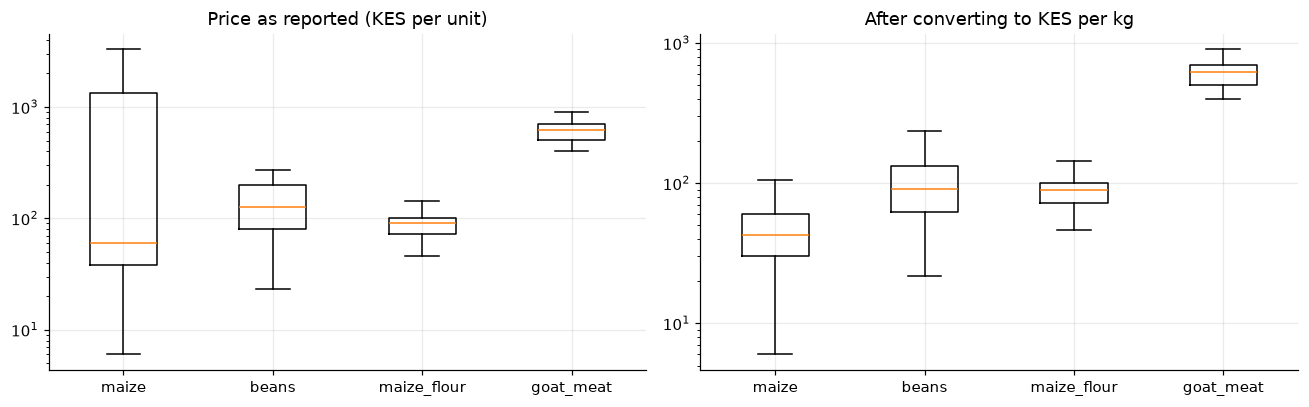

,count,mean,std,min,5%,50%,95%,max
staple,,,,,,,,
beans,3269.0,100.6,45.9,21.9,40.6,91.1,190.0,270.0
goat_meat,418.0,627.0,114.0,400.0,465.0,625.3,800.0,900.0
maize,4319.0,47.2,23.3,6.0,15.6,42.9,93.0,152.0
maize_flour,1515.0,88.7,20.4,46.0,56.9,90.0,120.0,195.0


In [8]:
order = ["maize", "beans", "maize_flour", "goat_meat"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].boxplot([st.loc[st.staple == s, "price"] for s in order], tick_labels=order, showfliers=False)
axes[0].set_yscale("log"); axes[0].set_title("Price as reported (KES per unit)")
axes[1].boxplot([st.loc[st.staple == s, "price_kg"] for s in order], tick_labels=order, showfliers=False)
axes[1].set_yscale("log"); axes[1].set_title("After converting to KES per kg")
plt.tight_layout(); plt.show()
st.groupby("staple").price_kg.describe(percentiles=[0.05, 0.5, 0.95]).round(1)

Seven WFP names map to SokoRadar's four staples, which make up a third of the file. Before conversion, a maize
"price" ranges from 6 to 8,138 shillings, because some rows are for a 90 kg bag. Per kg, the median price is 43 KES
for maize, 91 for beans, 90 for maize flour and 625 for goat meat.

### 1.5 Duplicate markets and outliers

In [9]:
from sokoradar.clean import _merge_markets, clean_prices
merged = _merge_markets(wfp, settings()["prep"]["market_merge_km"])
pairs = merged.loc[merged.market != merged.market_canon, ["market", "market_canon"]]
print(f"{len(pairs)} market names merged into another name within {settings()['prep']['market_merge_km']} km:")
print(pairs.rename(columns={"market_canon": "merged into"}).to_string(index=False))

st["market_std"] = st.market.map(dict(zip(merged.market, merged.market_canon)))
st["month"] = st.date.dt.to_period("M").dt.to_timestamp()
monthly = st.groupby(["market_std", "staple", "pricetype", "month"]).price_kg.median().rename("price").reset_index()
monthly["series"] = monthly.market_std + " | " + monthly.staple + " | " + monthly.pricetype

6 market names merged into another name within 15 km:
            market            merged into
 Marigat (Baringo) Marigat town (Baringo)
       Lodwar town       Lodwar (Turkana)
           Garissa Garissa town (Garissa)
     Marsabit town               Marsabit
Kitui town (Kitui)                  Kitui
      Mandera town                Mandera


In [10]:
res = clean_prices(wfp)
rows = []
for r in res.dropped_outliers.itertuples():
    s = monthly[(monthly.market_std == r.market) & (monthly.staple == r.commodity)
                & (monthly.pricetype == r.pricetype)].set_index("month").price
    others = s[s.index != r.month]
    rows.append({"market": r.market, "food": r.commodity, "type": r.pricetype, "month": f"{r.month:%b %Y}",
                 "price dropped (KES/kg)": round(r.price, 1),
                 "median of the series' other months": round(others.median(), 1), "months in the series": len(s)})
pd.DataFrame(rows)

,market,food,type,month,price dropped (KES/kg),median of the series' other months,months in the series
0,Kaanwa (Tharaka Nithi),maize,Wholesale,Feb 2024,25.0,32.2,22
1,Kitengela (Kajiado),maize,Wholesale,Jun 2021,8.9,47.5,30
2,Mandera,maize_flour,Retail,Dec 2024,50.0,130.0,8


Six market names are duplicates of another name a few kilometres away (for example *Garissa* and *Garissa town*)
and are merged. Three monthly prices are removed as unit slips: each sits more than 5 MADs from its series' rolling
median and is at least 2.5 times higher or lower. The table compares each one with the median of the rest of its
series.

### 1.6 Series length and the 36-month rule

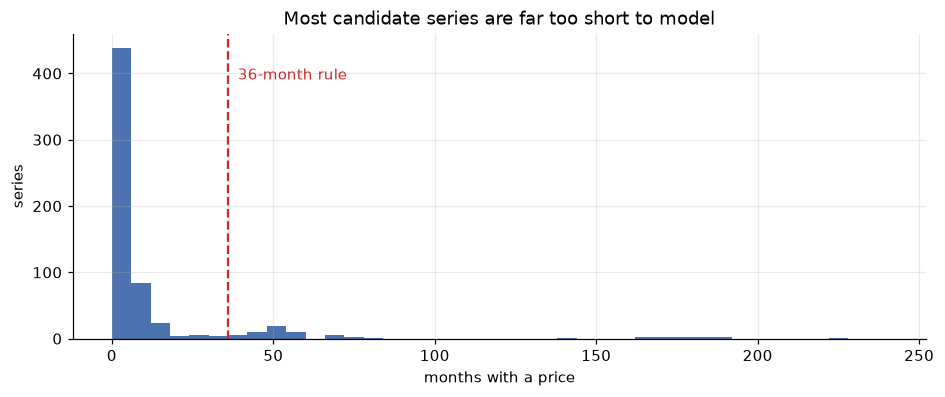

625 candidate series; median length 4 months; 522 have fewer than 12 months; 67 have 36 or more


{'series_before_filter': 625,
 'outliers_dropped': 3,
 'series_kept': 67,
 'observations_kept': 5386,
 'markets_kept': 30}

In [11]:
length = monthly.groupby("series").month.nunique()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.hist(length, bins=range(0, 241, 6), color="#4c72b0")
ax.axvline(36, color="#c92a2a", ls="--")
ax.text(39, ax.get_ylim()[1] * 0.85, "36-month rule", color="#c92a2a")
ax.set_xlabel("months with a price"); ax.set_ylabel("series")
ax.set_title("Most candidate series are far too short to model")
plt.show()
print(f"{len(length)} candidate series; median length {length.median():.0f} months; "
      f"{(length < 12).sum()} have fewer than 12 months; {(length >= 36).sum()} have 36 or more")
{k: res.quality[k] for k in ["series_before_filter", "outliers_dropped", "series_kept", "observations_kept", "markets_kept"]}

A *series* is one market, one food and one price type. The staples form 625 candidate series, but most are very
short: the median candidate has only 4 monthly prices, and 522 have fewer than 12. Only 67 reach the 36 months WFP
needs to estimate a seasonal pattern. Those 67 series, with 5,386 monthly prices from 30 markets, are what
SokoRadar models.

### 1.7 Gaps inside the kept series

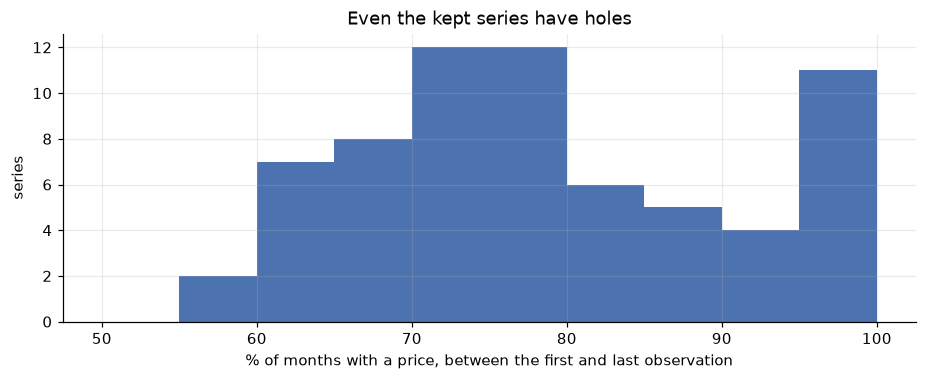

First year of each kept series: {2006: 13, 2008: 2, 2015: 8, 2018: 2, 2021: 42}


series  median_months  median_coverage
commodity   pricetype                                        
beans       Retail         16           53.5             0.78
            Wholesale       5          168.0             0.98
goat_meat   Retail          5           45.0             0.67
maize       Retail         20           54.0             0.78
            Wholesale       9          164.0             0.87
maize_flour Retail         12           51.5             0.73

In [12]:
from sokoradar.clean import series_table
ser = series_table(res.prices, res.markets)
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.hist(ser.coverage * 100, bins=range(50, 105, 5), color="#4c72b0")
ax.set_xlabel("% of months with a price, between the first and last observation"); ax.set_ylabel("series")
ax.set_title("Even the kept series have holes")
plt.show()
print("First year of each kept series:", ser.first_month.dt.year.value_counts().sort_index().to_dict())
ser.groupby(["commodity", "pricetype"]).agg(series=("series_id", "count"), median_months=("n_obs", "median"),
                                            median_coverage=("coverage", "median")).round(2)

The median kept series has a price in 78% of the months between its first and last observation, and the patchiest
has 57%. Missing months are never filled in: models and scores use only real prices. Wholesale maize and beans
have long histories (about 165 months), while 42 of the 67 series start in 2021, 38 of them in the camp markets.

### 1.8 Price histories

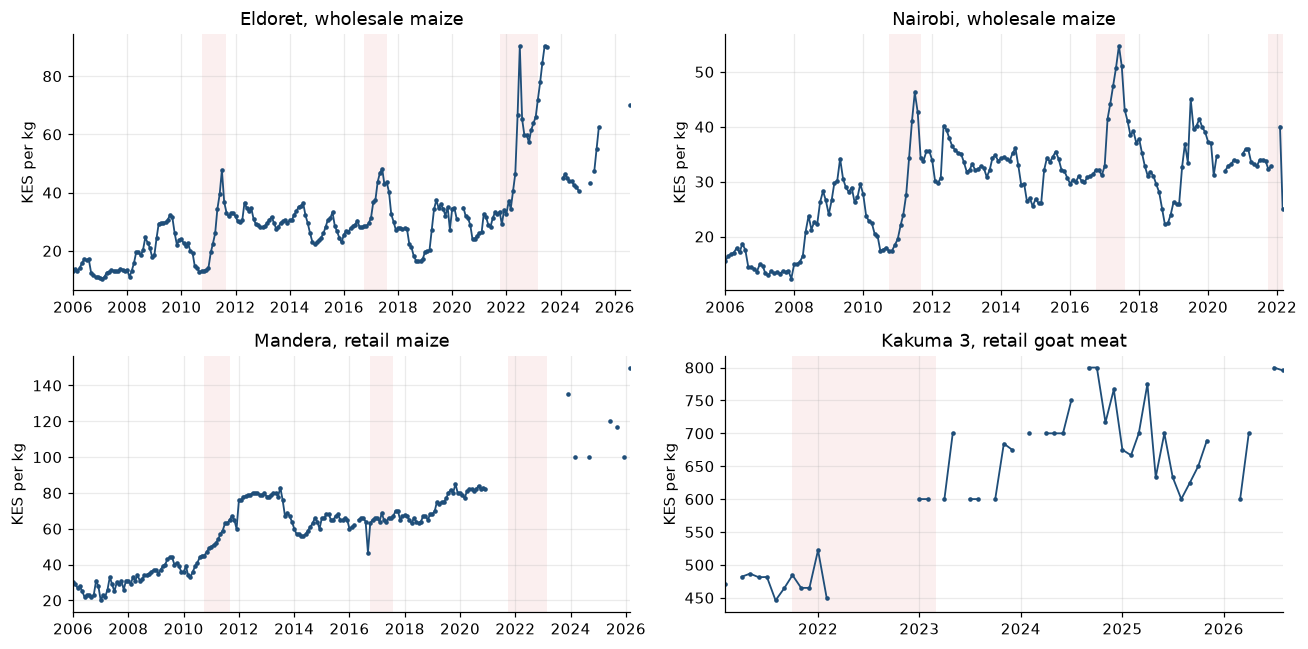

In [13]:
show = {"eldoret-town-uasin-gishu|maize|wholesale": "Eldoret, wholesale maize",
        "nairobi|maize|wholesale": "Nairobi, wholesale maize",
        "mandera|maize|retail": "Mandera, retail maize",
        "kakuma-3|goat_meat|retail": "Kakuma 3, retail goat meat"}
fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for ax, (sid, label) in zip(axes.flat, show.items()):
    s = res.prices[res.prices.series_id == sid].set_index("month").price.asfreq("MS")
    ax.plot(s.index, s.values, lw=1.2, color="#1f4e79", marker="o", markersize=2)
    shade(ax); ax.set_xlim(s.index.min(), s.index.max()); ax.set_title(label); ax.set_ylabel("KES per kg")
plt.tight_layout(); plt.show()

Prices jump in the drought years and drift upward with inflation. The 2011, 2017 and 2022–23 spikes stand out in
the long wholesale series; the camp series only start in 2021. Breaks in a line are months with no price.

### 1.9 Seasonality

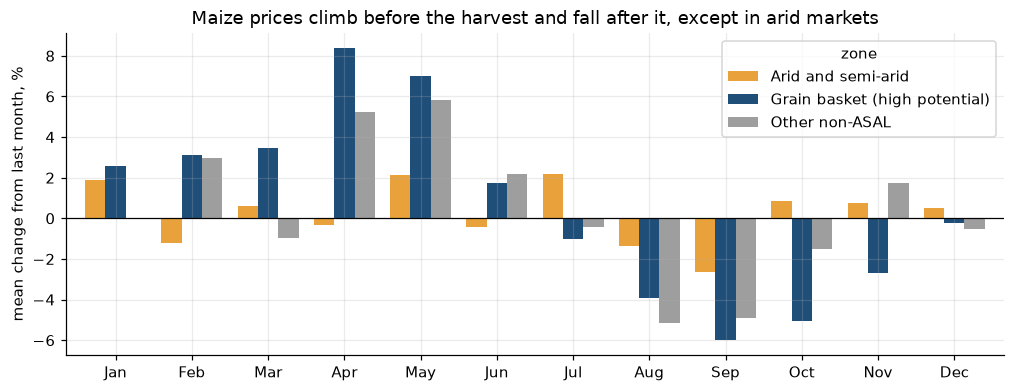

month,1,2,3,4,5,6,7,8,9,10,11,12
zone,,,,,,,,,,,,
Arid and semi-arid,1.9,-1.2,0.6,-0.3,2.1,-0.4,2.2,-1.4,-2.7,0.9,0.8,0.5
Grain basket (high potential),2.6,3.1,3.5,8.4,7.0,1.7,-1.0,-3.9,-6.0,-5.0,-2.7,-0.2
Other non-ASAL,0.0,3.0,-1.0,5.2,5.8,2.2,-0.4,-5.2,-4.9,-1.5,1.7,-0.5


In [14]:
mk_info = res.markets.set_index("market_key")[["county", "asal"]]
p = res.prices.join(mk_info, on="market_key").sort_values(["series_id", "month"])
p["change"] = 100 * np.log(p.price).groupby(p.series_id).diff()
p["next_month"] = p.groupby("series_id").month.diff().dt.days.between(28, 31)
grain = set(settings()["seasons"]["high_potential_counties"])
p["zone"] = np.where(p.county.isin(grain), "Grain basket (high potential)",
                     np.where(p.asal == "non-ASAL", "Other non-ASAL", "Arid and semi-arid"))
seas = p[p.next_month & (p.commodity == "maize")].groupby(["zone", p.month.dt.month]).change.mean().unstack(0)
ax = seas.plot.bar(figsize=(11, 3.8), width=0.8, color=["#e9a23b", "#1f4e79", "#9e9e9e"])
ax.set_xticklabels(MONTHS, rotation=0); ax.set_xlabel(""); ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("mean change from last month, %")
ax.set_title("Maize prices climb before the harvest and fall after it, except in arid markets")
plt.show()
seas.round(1).T

In the grain basket, maize prices climb before the harvest (+7 to +8% a month in April and May) and fall as it comes
in (−4 to −6% a month from August to October). The other non-ASAL markets, mainly the big cities, follow the same
calendar a little more weakly. In arid and semi-arid markets the swings stay within ±3%, because most of their maize
comes from elsewhere. The model therefore needs seasonal features that depend on where a market
is.

### 1.10 Markets move together

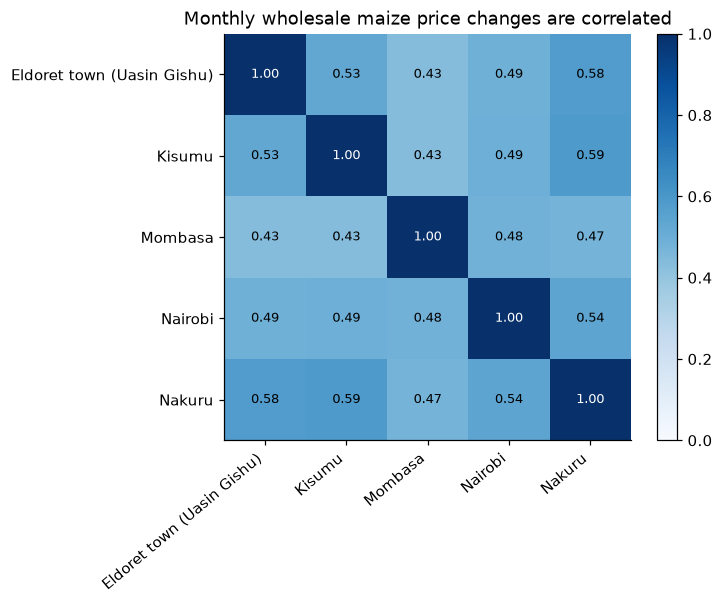

In [15]:
wh = res.prices[(res.prices.commodity == "maize") & (res.prices.pricetype == "Wholesale")]
wide = wh.pivot_table(index="month", columns="market", values="price")
wide = wide.loc[:, wide.notna().sum() > 100]
corr = np.log(wide).diff().corr(min_periods=60)
fig, ax = plt.subplots(figsize=(6, 4.8))
im = ax.imshow(corr, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=40, ha="right"); ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8.5,
                color="white" if corr.iloc[i, j] > 0.7 else "black")
ax.grid(False); plt.colorbar(im, ax=ax, fraction=0.046)
ax.set_title("Monthly wholesale maize price changes are correlated")
plt.show()

Month-to-month price changes in the five big wholesale maize markets are correlated at 0.43 to 0.59: the markets are
linked by trade. The model therefore reads a national price index, the gap to the Nairobi wholesale price and the gap
to the nearest market.

## 2. Markets and county boundaries (OCHA)

In [16]:
gpath = RAW / "ken_admin1.geojson"
geo = json.loads((gpath if gpath.exists() else ROOT / "config/ken_counties.geojson").read_text(encoding="utf-8"))
print(f"{len(geo['features'])} county shapes; properties: {list(geo['features'][0]['properties'])[:5]}")
mkts = pd.read_csv(RAW / FILES["markets"])
print(f"WFP market list: {len(mkts)} markets, {mkts.latitude.isna().sum()} without coordinates")
counties.asal.value_counts().rename("counties").to_frame()

47 county shapes; properties: ['adm1_name', 'adm1_name1', 'adm1_name2', 'adm1_name3', 'adm1_pcode']
WFP market list: 280 markets, 1 without coordinates


,counties
asal,
non-ASAL,24
semi-arid,14
arid,9


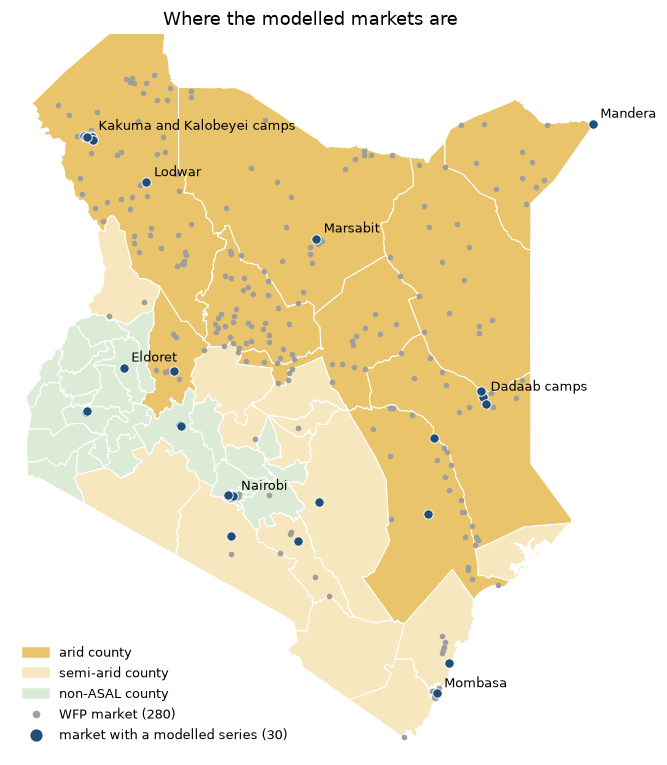

In [17]:
asal = counties.set_index("pcode").asal
colors = {"arid": "#e9c46a", "semi-arid": "#f6e7bf", "non-ASAL": "#dcebd5"}
fig, ax = plt.subplots(figsize=(7.5, 8.5))
for f in geo["features"]:
    pc = f["properties"].get("adm1_pcode") or f["properties"].get("pcode")
    g = f["geometry"]
    for poly in (g["coordinates"] if g["type"] == "MultiPolygon" else [g["coordinates"]]):
        ax.add_patch(Polygon(poly[0], closed=True, facecolor=colors.get(asal.get(pc), "#eeeeee"),
                             edgecolor="white", lw=0.7))
ax.scatter(mkts.longitude, mkts.latitude, s=7, color="#9e9e9e", zorder=3)
used = res.markets
ax.scatter(used.longitude, used.latitude, s=38, color="#1f4e79", edgecolor="white", lw=0.6, zorder=4)
lab = used.set_index("market_key")
for key, name in [("nairobi", "Nairobi"), ("eldoret-town-uasin-gishu", "Eldoret"), ("mombasa", "Mombasa"),
                  ("mandera", "Mandera"), ("kakuma-3", "Kakuma and Kalobeyei camps"), ("ifo-daadab", "Dadaab camps"),
                  ("lodwar-turkana", "Lodwar"), ("marsabit", "Marsabit")]:
    ax.annotate(name, (lab.loc[key, "longitude"], lab.loc[key, "latitude"]), xytext=(5, 4),
                textcoords="offset points", fontsize=8.5)
ax.set_xlim(33.7, 42.1); ax.set_ylim(-4.9, 5.2); ax.set_aspect("equal"); ax.grid(False)
ax.set_xticks([]); ax.set_yticks([])
for side in ax.spines.values():
    side.set_visible(False)
handles = [Patch(color=c, label=f"{k} county") for k, c in colors.items()] + [
    plt.Line2D([], [], marker="o", ls="", color="#9e9e9e", markersize=4, label=f"WFP market ({len(mkts)})"),
    plt.Line2D([], [], marker="o", ls="", color="#1f4e79", markersize=7,
               label=f"market with a modelled series ({len(used)})")]
ax.legend(handles=handles, loc="lower left", fontsize=8.5, frameon=False)
ax.set_title("Where the modelled markets are")
plt.show()

The 30 modelled markets are spread thinly: big cities and grain-basket markets in the west and centre, two on the
coast, and clusters in the arid north and east around the Kakuma, Kalobeyei and Dadaab camps. Most of the 280 WFP
markets, especially across the arid north, have too short a price history to model, which limits how much of the
country SokoRadar covers today.

## 3. CHIRPS rainfall

In [18]:
rain = pd.read_csv(RAW / FILES["rain"], dtype={"PCODE": str, "adm_level": str}, parse_dates=["date"])
print(f"{len(rain):,} rows, {rain.date.min():%b %Y} to {rain.date.max():%b %Y}; "
      f"dekads start on days {sorted(rain.date.dt.day.unique().tolist())}")
print(rain.groupby("adm_level").PCODE.agg(areas="nunique", rows="size"))
print("version:", rain.version.value_counts().to_dict(),
      f"| preliminary since {rain.loc[rain.version == 'prelim', 'date'].min():%b %Y}")
rain.head(3)

133,488 rows, Jan 1981 to Oct 2026; dekads start on days [1, 11, 21]
           areas    rows
adm_level               
1              8   13184
2             73  120304
version: {'final': 133164, 'prelim': 324} | preliminary since Sep 2026


,date,adm_level,adm_id,PCODE,n_pixels,rfh,rfh_avg,r1h,r1h_avg,r3h,r3h_avg,rfq,r1q,r3q,version
0,1981-01-01,1,51325,KE019,427.0,7.372365,15.759407,NaN,NaN,NaN,NaN,59.598840,NaN,NaN,final
1,1981-01-11,1,51325,KE019,427.0,4.325527,19.294770,NaN,NaN,NaN,NaN,38.384920,NaN,NaN,final
2,1981-01-21,1,51325,KE019,427.0,5.569087,16.265417,17.26698,51.319595,NaN,NaN,49.700817,39.536823,NaN,final


| Column | Meaning |
|---|---|
| `rfh` | rainfall in the 10-day period (dekad), mm |
| `rfh_avg` | long-term average for that dekad, mm |
| `r1h`, `r3h` | rolling 1-month and 3-month totals, mm |
| `rfq`, `r1q`, `r3q` | the same as % of the long-term average (100 = normal) |
| `n_pixels` | satellite pixels in the area, used as weights |

In [19]:
dist = rain[rain.adm_level == "2"].assign(county_pcode=lambda d: d.PCODE.str[:5])
print(f"{dist.PCODE.nunique()} districts roll up into {dist.county_pcode.nunique()} counties")
print("Counties without rainfall data:", sorted(set(counties.pcode) - set(dist.county_pcode)) or "none")
(rain.isna().mean() * 100).round(2).rename("% missing").to_frame().T

73 districts roll up into 47 counties
Counties without rainfall data: none


,date,adm_level,adm_id,PCODE,n_pixels,rfh,rfh_avg,r1h,r1h_avg,r3h,r3h_avg,rfq,r1q,r3q,version
% missing,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.12,0.12,0.49,0.49,0.0,0.12,0.49,0.0


The file holds two levels: 8 large former provinces (`adm_level` 1, not used) and 73 pre-2013 districts
(`adm_level` 2). Each district code starts with its county code, so the districts roll up into all 47 of today's
counties, weighted by their number of pixels. The few missing values are the rolling totals at the very start of
the record, and the last two months are still preliminary.

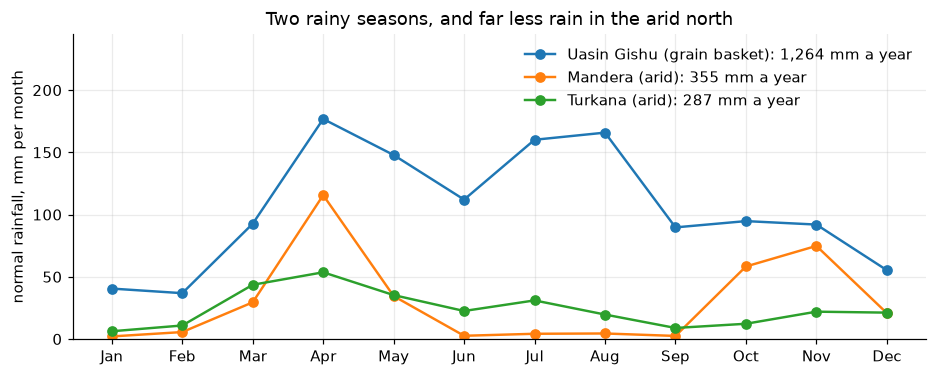

In [20]:
yr = dist[dist.date.dt.year == 2020].assign(w=lambda d: d.rfh_avg * d.n_pixels)
cl = yr.groupby(["county_pcode", "date"]).agg(w=("w", "sum"), n=("n_pixels", "sum")).reset_index()
cl["mm"] = cl.w / cl.n
normal = cl.groupby(["county_pcode", cl.date.dt.month]).mm.sum().unstack(0)
fig, ax = plt.subplots(figsize=(10, 3.6))
for county, label in {"Uasin Gishu": "Uasin Gishu (grain basket)", "Mandera": "Mandera (arid)",
                      "Turkana": "Turkana (arid)"}.items():
    s = normal[PCODE[county]]
    ax.plot(range(1, 13), s, marker="o", lw=1.6, label=f"{label}: {s.sum():,.0f} mm a year")
ax.set_xticks(range(1, 13), MONTHS); ax.set_ylabel("normal rainfall, mm per month"); ax.set_ylim(0, 245)
ax.legend(frameon=False, loc="upper right")
ax.set_title("Two rainy seasons, and far less rain in the arid north")
plt.show()

Kenya has two rainy seasons: the long rains (March to May) and the short rains (October to December). The grain
basket (Uasin Gishu) gets 1,264 mm a year and stays wet from March to November. Mandera gets 355 mm, almost all of it
in April and October–November, and Turkana 287 mm, spread thinly through the year. In such dry counties a single
failed season hits hard.

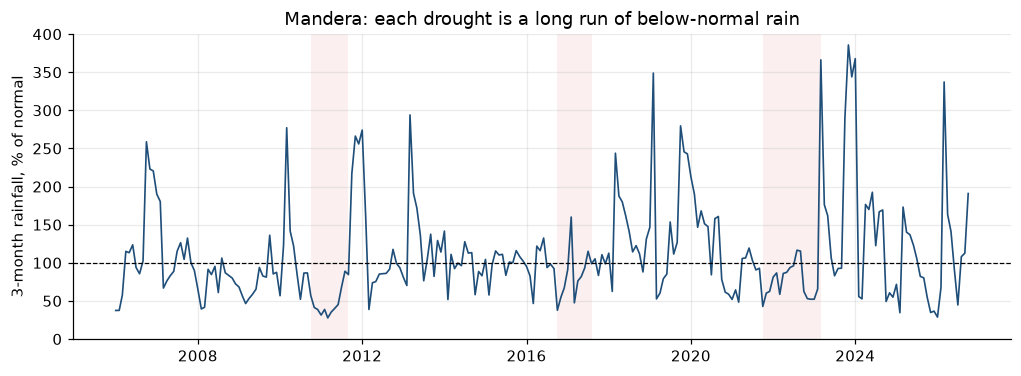

County-months capped at 400% of normal: 0.3%


In [21]:
from sokoradar.climate import climate_monthly
clim = climate_monthly()
man = clim[clim.county_pcode == PCODE["Mandera"]].set_index("month").loc["2006":]
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(man.index, man.rain_3m_pct, color="#1f4e79", lw=1.1)
ax.axhline(100, color="black", lw=0.8, ls="--"); shade(ax)
ax.set_ylabel("3-month rainfall, % of normal"); ax.set_ylim(0, 400)
ax.set_title("Mandera: each drought is a long run of below-normal rain")
plt.show()
print(f"County-months capped at 400% of normal: {(clim.rain_1m_pct >= 400).mean():.1%}")

Each drought shows up as a long run below normal. In Mandera, three-month rainfall stayed at 28–45% of normal from
November 2010 to June 2011, and fell to 38% in October 2016 and 43% in October 2021. In dry months the long-term
average is close to zero, so "% of normal" can reach extreme values; the pipeline caps it at 400%, which affects
0.3% of county-months.

## 4. MODIS vegetation index (NDVI)

| Column | Meaning |
|---|---|
| `vim` | NDVI for the dekad, from 0 (bare ground) to about 0.9 (dense green vegetation) |
| `vim_avg` | long-term average for that dekad |
| `viq` | `vim` as % of the long-term average (100 = normal) |

In [22]:
ndvi = pd.read_csv(RAW / FILES["ndvi"], dtype={"PCODE": str, "adm_level": str}, parse_dates=["date"])
print(f"{len(ndvi):,} rows, {ndvi.date.min():%b %Y} to {ndvi.date.max():%b %Y}, "
      f"{ndvi.PCODE.nunique()} areas (same districts as the rainfall file), missing values: {int(ndvi.isna().sum().sum())}")
ndvi[["vim", "vim_avg", "viq"]].describe().round(2)

70,713 rows, Jul 2002 to Sep 2026, 81 areas (same districts as the rainfall file), missing values: 0


,vim,vim_avg,viq
count,70713.00,70713.00,70713.00
mean,0.56,0.55,101.64
std,0.16,0.16,10.45
min,0.07,0.11,62.05
25%,0.45,0.45,96.40
50%,0.60,0.59,101.08
75%,0.69,0.67,105.91
max,0.84,0.82,192.78


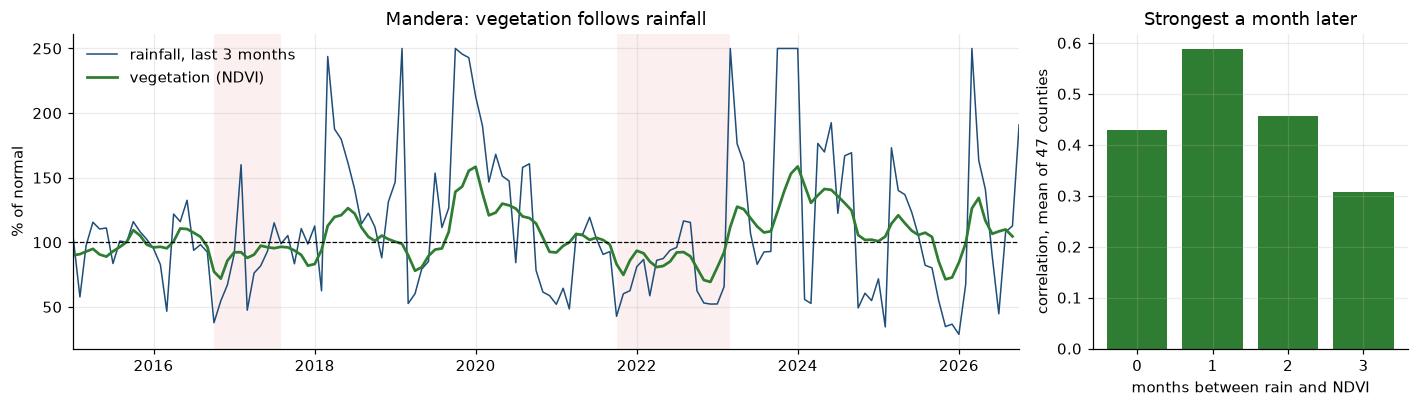

lag,0,1,2,3
mean correlation,0.43,0.59,0.46,0.31


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [3, 1]})
m2 = man.loc["2015":]
axes[0].plot(m2.index, m2.rain_3m_pct.clip(upper=250), color="#1f4e79", lw=1, label="rainfall, last 3 months")
axes[0].plot(m2.index, m2.ndvi_pct, color="#2e7d32", lw=1.8, label="vegetation (NDVI)")
axes[0].axhline(100, color="black", lw=0.8, ls="--"); shade(axes[0]); axes[0].legend(frameon=False)
axes[0].set_xlim(m2.index.min(), m2.index.max())
axes[0].set_ylabel("% of normal"); axes[0].set_title("Mandera: vegetation follows rainfall")
lags = []
for pc, g in clim.groupby("county_pcode"):
    g = g.sort_values("month").set_index("month")
    for lag in range(4):
        lags.append({"lag": lag, "corr": g.rain_1m_pct.shift(lag).corr(g.ndvi_pct)})
lag_corr = pd.DataFrame(lags).groupby("lag")["corr"].mean()
axes[1].bar(lag_corr.index, lag_corr.values, color="#2e7d32")
axes[1].set_xticks(range(4)); axes[1].set_xlabel("months between rain and NDVI")
axes[1].set_ylabel("correlation, mean of 47 counties"); axes[1].set_title("Strongest a month later")
plt.tight_layout(); plt.show()
lag_corr.round(2).rename("mean correlation").to_frame().T

Vegetation follows rain with a delay of about a month: one month's rainfall correlates most strongly with NDVI a
month later (0.59 on average across counties, against 0.43 in the same month). NDVI adds a smoother, slightly later
view of the same drought signal, and it measures pasture directly, which matters for herders.

## 5. Exchange rate (Central Bank of Kenya)

In [24]:
fx_raw = pd.read_csv(RAW / FILES["cbk"], header=None, names=["date", "currency", "mean", "buy", "sell"], dtype=str)
iso = fx_raw.date.str.contains("-", na=False)
print(f"{len(fx_raw):,} rows, no header row, {fx_raw.currency.str.strip().nunique()} currency labels")
print(f"dates as dd/mm/yyyy: {(~iso).sum():,} rows; as yyyy-mm-dd: {iso.sum():,} rows; "
      f"exact duplicate rows: {fx_raw.duplicated().sum():,}")
fx_raw[fx_raw.currency.str.contains("US DOLLAR", na=False)].iloc[[0, 1, -2, -1]]

37,877 rows, no header row, 23 currency labels
dates as dd/mm/yyyy: 13 rows; as yyyy-mm-dd: 37,864 rows; exact duplicate rows: 485


,date,currency,mean,buy,sell
17,2016-10-11,US DOLLAR,101.2847,101.1889,101.3806
32,2016-10-13,US DOLLAR,101.2953,101.1994,101.3911
37835,2024-01-02,US DOLLAR,157.3235,156.9529412,157.6941176
37856,2024-01-03,US DOLLAR,157.3235,156.9529412,157.6941176


CBK dollar rate: 88 months, Oct 2016 to Jan 2024
WFP-implied rate vs CBK over 79 shared months: mean absolute difference 0.16%


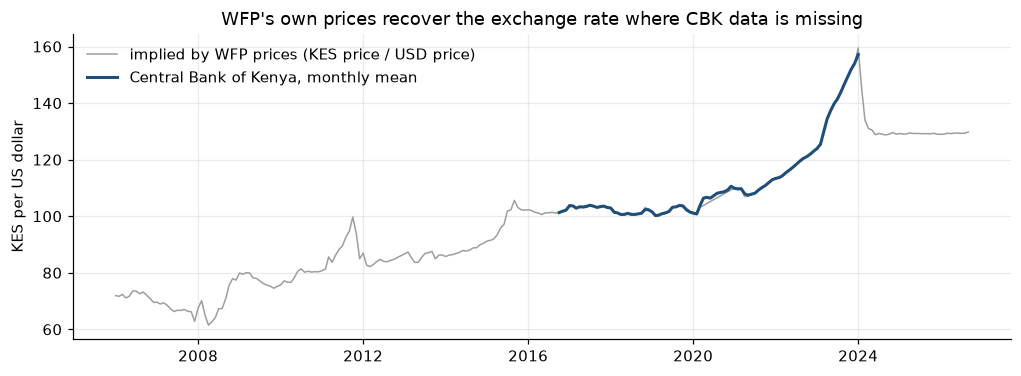

In [25]:
from sokoradar.macro import cbk_fx, wfp_implied_fx, fx_monthly
cbk = cbk_fx().dropna(subset=["kes_usd"])
implied = wfp_implied_fx(wfp)
both = cbk.merge(implied, on="month")
print(f"CBK dollar rate: {len(cbk)} months, {cbk.month.min():%b %Y} to {cbk.month.max():%b %Y}")
print(f"WFP-implied rate vs CBK over {len(both)} shared months: "
      f"mean absolute difference {100 * (both.kes_usd / both.kes_usd_wfp - 1).abs().mean():.2f}%")
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(implied.month, implied.kes_usd_wfp, color="#9e9e9e", lw=1, label="implied by WFP prices (KES price / USD price)")
ax.plot(cbk.month, cbk.kes_usd, color="#1f4e79", lw=2, label="Central Bank of Kenya, monthly mean")
ax.set_ylabel("KES per US dollar"); ax.legend(frameon=False)
ax.set_title("WFP's own prices recover the exchange rate where CBK data is missing")
plt.show()

The CBK file has no header row, mixes two date formats (`11/10/2016` and `2024-01-02`) and repeats rows. Its dollar
rate covers only October 2016 to January 2024. Over the months both exist, the rate implied by WFP's own shilling
and dollar prices is within 0.2% of CBK's, so the pipeline uses it before October 2016 and after January 2024. The
shilling weakened from about 67 per dollar in 2007 to 157 in January 2024, then recovered to about 129.

## 6. World Bank commodity prices (Pink Sheet)

In [26]:
xl = pd.ExcelFile(RAW / FILES["pink"])
print("Sheets:", xl.sheet_names)
pd.read_excel(xl, sheet_name="Monthly Prices", header=None, nrows=8).iloc[:, :5]

Sheets: ['Mismatch Details', 'Monthly Prices', 'Monthly Indices', 'Description', 'Index Weights']


,0,1,2,3,4
0,World Bank Commodity Price Data (The Pink Sheet),NaN,NaN,NaN,NaN
1,"monthly prices in nominal US dollars, 1960 to ...",NaN,NaN,NaN,NaN
2,(monthly series are available only in nominal ...,NaN,NaN,NaN,NaN
3,"Updated on October 02, 2026",NaN,NaN,NaN,NaN
4,NaN,"Crude oil, average","Crude oil, Brent","Crude oil, Dubai","Crude oil, WTI"
5,NaN,($/bbl),($/bbl),($/bbl),($/bbl)
6,1960M01,1.6,1.6,1.6,…
7,1960M02,1.6,1.6,1.6,…


The sheet has title rows on top, the series names on row 4 and units on row 5. Periods are written `1960M01`, and
missing values are `…`. The pipeline finds the header row by its first name ("Crude oil") rather than a fixed row
number, because the World Bank changes the layout from time to time.

Monthly from Jan 1960 to Sep 2026


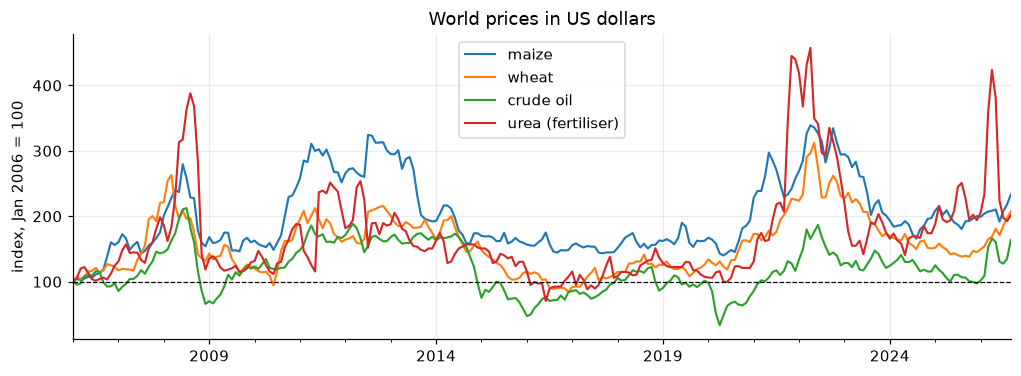

In [27]:
from sokoradar.macro import pink_sheet
ps = pink_sheet().set_index("month")
names = {"global_maize_usd": "maize", "global_wheat_usd": "wheat", "global_crude_oil_usd": "crude oil",
         "global_urea_usd": "urea (fertiliser)"}
recent = ps.loc["2006":, list(names)].rename(columns=names)
print(f"Monthly from {ps.index.min():%b %Y} to {ps.index.max():%b %Y}")
ax = (100 * recent / recent.iloc[0]).plot(figsize=(11, 3.6), lw=1.4)
ax.axhline(100, color="black", lw=0.8, ls="--"); ax.set_ylabel("index, Jan 2006 = 100"); ax.set_xlabel("")
ax.set_title("World prices in US dollars")
plt.show()

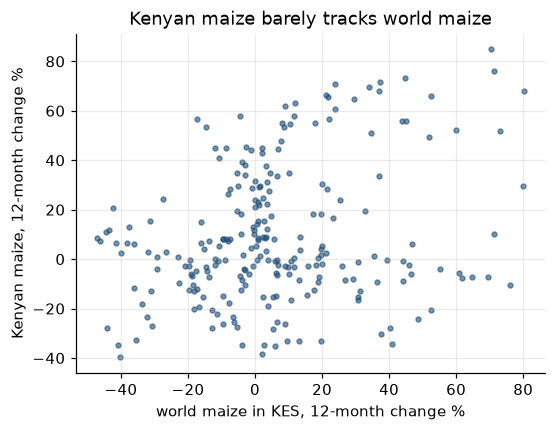

,Kenyan maize (national index),world maize in KES,KES per USD
Kenyan maize (national index),1.00,0.27,0.35
world maize in KES,0.27,1.00,0.10
KES per USD,0.35,0.10,1.00


In [28]:
fx = fx_monthly(wfp).set_index("month")
mz = res.prices[res.prices.commodity == "maize"].sort_values(["series_id", "month"]).copy()
mz["dlog"] = np.log(mz.price).groupby(mz.series_id).diff()
mz.loc[mz.groupby("series_id").month.diff().dt.days > 31, "dlog"] = np.nan
nat = (mz.groupby("month").dlog.median()
       .reindex(pd.date_range(mz.month.min(), mz.month.max(), freq="MS")).fillna(0).cumsum())
world_kes = np.log(ps.global_maize_usd * fx.kes_usd).dropna()
chg = pd.DataFrame({"Kenyan maize (national index)": nat.diff(12), "world maize in KES": world_kes.diff(12),
                    "KES per USD": np.log(fx.kes_usd).diff(12)}).dropna() * 100
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.scatter(chg["world maize in KES"], chg["Kenyan maize (national index)"], s=10, alpha=0.6, color="#1f4e79")
ax.set_xlabel("world maize in KES, 12-month change %"); ax.set_ylabel("Kenyan maize, 12-month change %")
ax.set_title("Kenyan maize barely tracks world maize")
plt.show()
chg.corr().round(2)

World prices spiked in 2008, 2011–12 and 2022. Kenyan maize follows them only loosely: its 12-month changes
correlate at just 0.27 with world maize priced in shillings (and 0.35 with the exchange rate alone). Kenya's maize market runs mostly on
its own harvests and regional trade. This matches the ablation test in the report, where adding Pink Sheet features
made forecasts worse, so they are left out of the production model.

## 7. World Bank Real-Time Food Prices (RTFP)

In [29]:
cols = pd.read_csv(RAW / FILES["rtfp"], nrows=0).columns
kind = (pd.Series(cols).str.extract(r"^(o|h|l|c|inflation|trust)_")[0]
        .map({"o": "open (o_)", "h": "high (h_)", "l": "low (l_)", "c": "close estimate (c_)",
              "inflation": "inflation_", "trust": "trust_"})
        .fillna("observed price or descriptor"))
print(f"{len(cols)} columns")
kind.value_counts().rename_axis("column type").rename("columns").to_frame()

732 columns


,columns
column type,
observed price or descriptor,120
open (o_),102
high (h_),102
low (l_),102
close estimate (c_),102
inflation_,102
trust_,102


55,224 market-months, 234 markets, Jan 2007 to Aug 2026


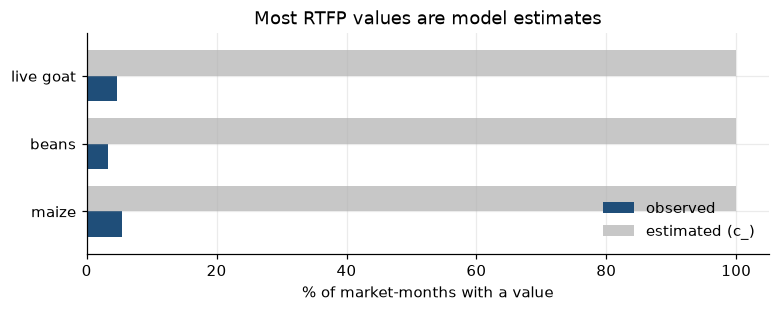

,observed,estimated (c_)
maize,5.4,100.0
beans,3.3,100.0
live goat,4.6,100.0


In [30]:
pairs = {"maize": "maize_fao", "beans": "beans", "live goat": "livestock_goat_s_fao"}
use = ["mkt_name", "DATES"] + list(pairs.values()) + ["c_" + c for c in pairs.values()]
rt = pd.read_csv(RAW / FILES["rtfp"], usecols=use, low_memory=False, parse_dates=["DATES"])
print(f"{len(rt):,} market-months, {rt.mkt_name.nunique()} markets, {rt.DATES.min():%b %Y} to {rt.DATES.max():%b %Y}")
share = pd.DataFrame({
    "observed": [100 * pd.to_numeric(rt[c], errors="coerce").notna().mean() for c in pairs.values()],
    "estimated (c_)": [100 * pd.to_numeric(rt["c_" + c], errors="coerce").notna().mean() for c in pairs.values()]},
    index=list(pairs))
ax = share.plot.barh(figsize=(8, 2.6), color=["#1f4e79", "#c7c7c7"], width=0.75)
ax.set_xlabel("% of market-months with a value"); ax.legend(frameon=False, loc="lower right")
ax.set_title("Most RTFP values are model estimates")
plt.show()
share.round(1)

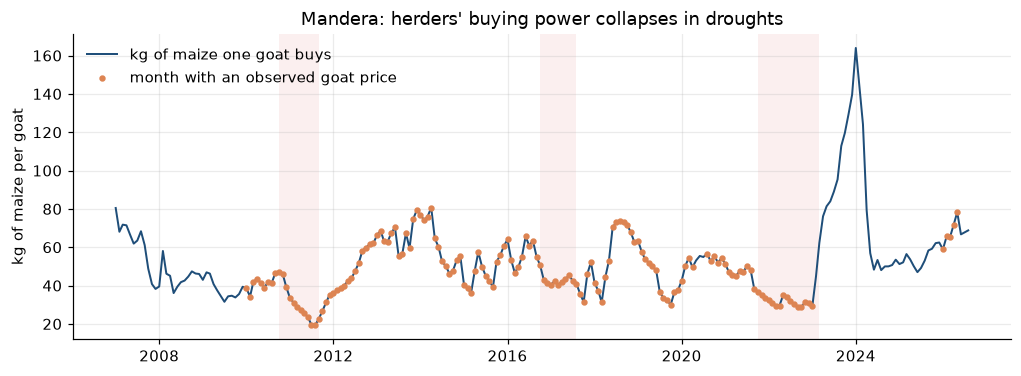

Typical month: 49 kg; lowest: 19 kg in August 2011


In [31]:
m = rt[rt.mkt_name == "Mandera"].set_index("DATES").sort_index()
tot = m.c_livestock_goat_s_fao / m.c_maize_fao
observed = pd.to_numeric(m.livestock_goat_s_fao, errors="coerce").notna()
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(tot.index, tot, color="#1f4e79", lw=1.3, label="kg of maize one goat buys")
ax.scatter(tot.index[observed], tot[observed], s=10, color="#dd8452", zorder=3, label="month with an observed goat price")
shade(ax); ax.set_ylabel("kg of maize per goat"); ax.legend(frameon=False)
ax.set_title("Mandera: herders' buying power collapses in droughts")
plt.show()
print(f"Typical month: {tot.median():.0f} kg; lowest: {tot.min():.0f} kg in {tot.idxmin():%B %Y}")

Only 3–5% of RTFP values were observed; the `c_` columns fill every other market and month with model estimates.
Learning from them would mean learning from another model, so SokoRadar never uses RTFP as a target or to test
forecasts. It uses only the goat prices, which WFP does not collect, to track pastoral terms of trade. In Mandera, a
goat bought about 49 kg of maize in a typical month but only 19 kg in August 2011, at the height of the drought. Orange
dots mark months with an observed goat price; the rest of the line is estimated.

## 8. Joining the datasets: a first look at the drivers

Each kept maize price is linked to its county's rainfall and vegetation in the same month, and to the price three
months later.

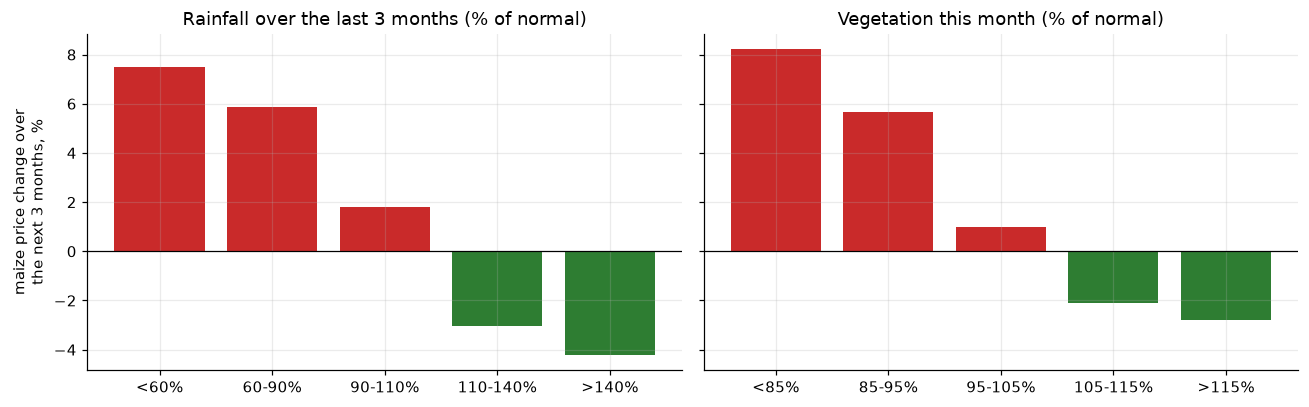

rain_3m_pct,<60%,60-90%,90-110%,110-140%,>140%
mean,7.5,5.9,1.8,-3.1,-4.2
count,291.0,671.0,429.0,504.0,539.0


ndvi_pct,<85%,85-95%,95-105%,105-115%,>115%
mean,8.2,5.7,1.0,-2.1,-2.8
count,231.0,497.0,733.0,487.0,486.0


In [32]:
pm = res.prices.merge(res.markets[["market_key", "county_pcode"]], on="market_key")
pm["logp"] = np.log(pm.price)
ahead = (pm[["series_id", "month", "logp"]].assign(month=lambda d: d.month - pd.DateOffset(months=3))
         .rename(columns={"logp": "logp_3m"}))
pm = pm.merge(ahead, on=["series_id", "month"], how="left")
pm["change_3m_pct"] = 100 * (pm.logp_3m - pm.logp)
j = pm[pm.commodity == "maize"].merge(clim, on=["county_pcode", "month"], how="left").dropna(subset=["change_3m_pct"])
rain_bins = pd.cut(j.rain_3m_pct, [0, 60, 90, 110, 140, 400], include_lowest=True,
                   labels=["<60%", "60-90%", "90-110%", "110-140%", ">140%"])
ndvi_bins = pd.cut(j.ndvi_pct, [0, 85, 95, 105, 115, 300], labels=["<85%", "85-95%", "95-105%", "105-115%", ">115%"])
by_rain = j.groupby(rain_bins, observed=True).change_3m_pct.agg(["mean", "count"])
by_ndvi = j.groupby(ndvi_bins, observed=True).change_3m_pct.agg(["mean", "count"])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, tab, title in [(axes[0], by_rain, "Rainfall over the last 3 months (% of normal)"),
                       (axes[1], by_ndvi, "Vegetation this month (% of normal)")]:
    ax.bar(tab.index.astype(str), tab["mean"], color=["#c92a2a" if v > 0 else "#2e7d32" for v in tab["mean"]])
    ax.axhline(0, color="black", lw=0.8); ax.set_title(title)
axes[0].set_ylabel("maize price change over\nthe next 3 months, %")
plt.tight_layout(); plt.show()
display(by_rain.round(1).T, by_ndvi.round(1).T)

The link the model relies on is visible in the raw data. After three months with less than 60% of normal rain, maize
prices rose 7.5% on average over the next three months; after more than 140%, they fell 4.2%. Vegetation shows the
same gradient: +8.2% below 85% of normal, −2.8% above 115%.

## 9. What the EDA means for the model

| Finding | What the pipeline does |
|---|---|
| Mixed units and several names for the same food | Convert every price to KES per kg; map seven WFP names to four staples |
| Six markets appear under two names | Merge names that share a base and lie within 15 km |
| Three prices off by a factor of 2.5 or more | Drop them (5 MADs and 2.5× rule) |
| Only 67 of 625 candidate series have 36+ months | Model those 67; never fill a missing month |
| Most live series are camp markets that start in 2021 | Report accuracy by segment, not only overall |
| Prices move together across markets | Market-network features: national index, Nairobi gap, nearest-market gap |
| Strong pre-harvest rise in the grain basket only | Seasonal features plus harvest and lean-season flags by zone |
| Dry spells come before price rises; NDVI follows rain by about a month | Rainfall and NDVI features lagged 0–5 months |
| Rainfall % of normal explodes in dry months | Cap at 400% |
| Climate data comes as 73 old districts | Roll up to 47 counties, weighted by pixels |
| CBK dollar rate stops in January 2024 | Fill with the WFP-implied rate (within 0.2% of CBK) |
| World prices barely track Kenyan maize | Tested in the ablation, left out of production |
| RTFP is mostly model estimates | Use only its goat prices, for terms of trade; never as truth |